In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D



In [8]:
df = pd.read_csv("exoplanet.eu_catalog_19-10-26_21_14_26.csv")

In [101]:
getradials = df["detection_type"] == "Radial Velocity"
gettransit = df["detection_type"] == "Primary Transit"
getmicrolensing = df["detection_type"] == "Microlensing"
getimaging = df["detection_type"] == "Imaging"

radials = df[getradials]
transits = df[gettransit]
microlenses = df[getmicrolensing]
imaged = df[getimaging]

In [102]:
catalog_list = [df, radials, transits, microlenses, imaged]

Text(0.5, 0, 'Planetary Mass in Jupiter Masses')

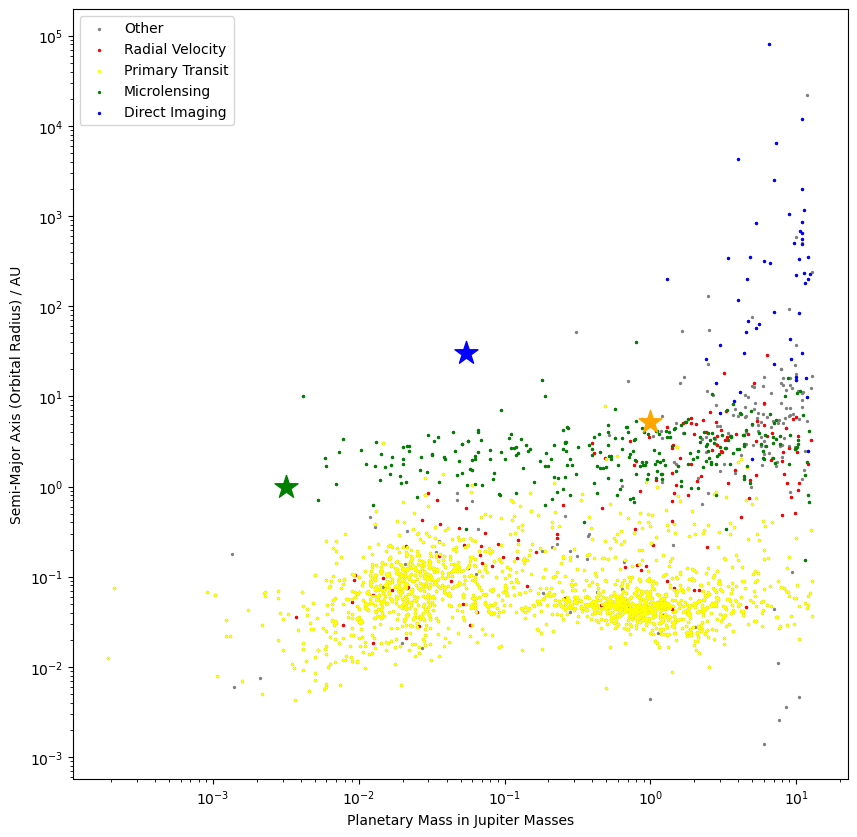

In [103]:
catalog_list = [df, radials, transits, microlenses, imaged]
colors = ["gray", "red", "yellow", "green", "blue", "gray"]
labels = ["Other", "Radial Velocity", "Primary Transit", "Microlensing", "Direct Imaging"]

plt.figure(figsize=(10,10))

i=0
for dict in catalog_list:

    plt.scatter(dict["mass"], dict["semi_major_axis"], s=2, c=colors[i], label=labels[i], alpha=1)
    i += 1

plt.xscale("log")
plt.yscale("log")
plt.scatter(1, 5.20, marker="*", s=300, color='orange')
plt.scatter(0.00315 , 1, marker="*", s=300, color='green')
plt.scatter(0.054, 30.07, marker="*", s=300, color='blue')
plt.legend()
plt.ylabel("Semi-Major Axis (Orbital Radius) / AU")
plt.xlabel("Planetary Mass in Jupiter Masses")

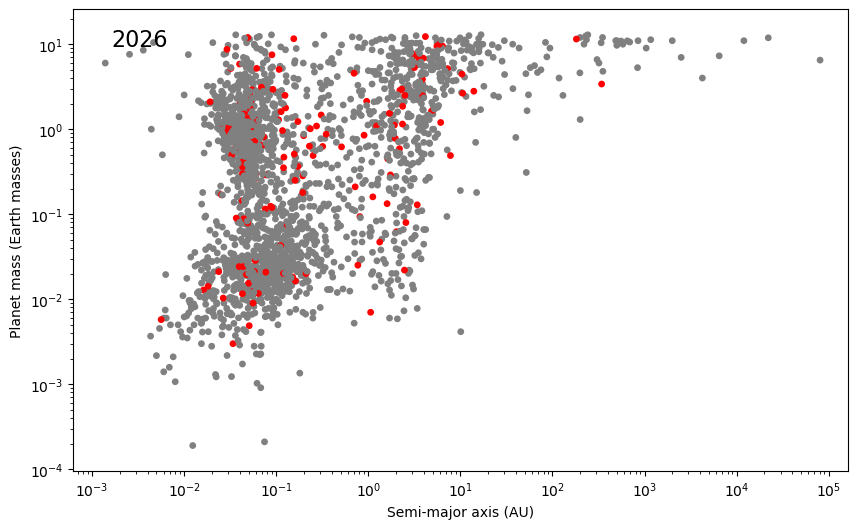

In [ ]:
# Drop rows missing any needed value
years = np.arange(df['discovered'].min(), df['discovered'].max() + 1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(df['semi_major_axis'].min() * 0.5, df['semi_major_axis'].max() * 2)
ax.set_ylim(df['mass'].min() * 0.5, df['mass'].max() * 2)
ax.set_xlabel('Semi-major axis (AU)')
ax.set_ylabel('Planet mass (Earth masses)')

scat = ax.scatter([], [], s=15)
year_text = ax.text(0.05, 0.92, '', transform=ax.transAxes, fontsize=16)

def update(year):
    seen = df[df['discovered'] <= year]
    scat.set_offsets(seen[['semi_major_axis', 'mass']].to_numpy())

    # Highlight this year's discoveries
    colors = np.where(seen['discovered'] == year, 'red', 'gray')
    scat.set_facecolor(colors)

    year_text.set_text(str(year))
    return scat, year_text

frames = np.arange(years.min(), years.max() + 1)
hold = 5                                             # extra frames on the last year
frames = np.concatenate([frames, np.full(hold, frames[-1])])

anim = FuncAnimation(fig, update, frames=frames, interval=300, blit=True)
anim.save('exoplanets.gif', writer=PillowWriter(fps=4))
plt.show()

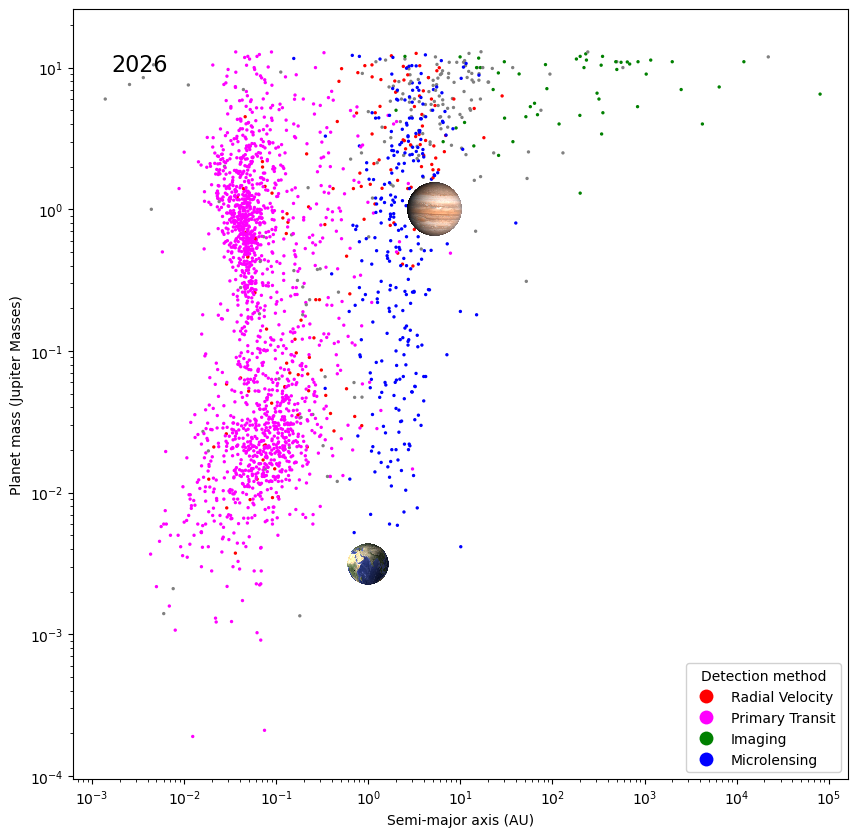

In [14]:
# Drop rows missing any needed value
years = np.arange(df['discovered'].min(), df['discovered'].max() + 1)

color_map = {
    'Radial Velocity' : 'red',
    'Primary Transit' : 'magenta',
    'Imaging' : 'green',
    'Microlensing' : 'blue'
}

df['color'] = df['detection_type'].map(color_map).fillna('gray')
years = np.arange(df['discovered'].min(), df['discovered'].max() + 1)

fig, ax = plt.subplots(figsize=(10,10))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(df['semi_major_axis'].min() * 0.5, df['semi_major_axis'].max() * 2)
ax.set_ylim(df['mass'].min() * 0.5, df['mass'].max() * 2)
ax.set_xlabel('Semi-major axis (AU)')
ax.set_ylabel('Planet mass (Jupiter Masses)')

# Create Legend
handles = [
    Line2D([0], [0], marker='o', linestyle='', markersize=10,
           markerfacecolor=c, markeredgecolor='none', label=label)
    for label, c in color_map.items()
]

legend = ax.legend(handles=handles, title='Detection method',
                   loc='lower right', framealpha=0.9)

# Setting scatterplot proper
scat = ax.scatter([], [], s=2)
year_text = ax.text(0.05, 0.92, '', transform=ax.transAxes, fontsize=16)

img = plt.imread('jupiter.png')            # ideally a PNG with a transparent background
imagebox = OffsetImage(img, zoom=0.05)     # adjust zoom to taste

jupiter = AnnotationBbox(
    imagebox,
    (5.2,1),            # (mass in M_j, semi major axis in AU)
    xycoords='data',
    frameon=False,           # no border box around the image
    box_alignment=(0.5, 0.5),  # image center sits on the point
    zorder=10,               # draw above the scatter points
)
jupiter.set_animated(True)   # needed for correct layering with blit=True (see below)
ax.add_artist(jupiter)

img = plt.imread('earth.png')            # ideally a PNG with a transparent background
imagebox = OffsetImage(img, zoom=0.03)     # adjust zoom to taste

earth = AnnotationBbox(
    imagebox,
    (1, 0.00315),            # (mass in M_j, semi major axis in AU)
    xycoords='data',
    frameon=False,           # no border box around the image
    box_alignment=(0.5, 0.5),  # image center sits on the point
    zorder=10,               # draw above the scatter points
)
earth.set_animated(True)   # needed for correct layering with blit=True (see below)
ax.add_artist(earth)

def update(year):
    seen = df[df['discovered'] <= year]
    scat.set_offsets(seen[['semi_major_axis', 'mass']].to_numpy())

    scat.set_facecolor(seen['color'])

    year_text.set_text(str(year))
    return scat, year_text, jupiter, earth

frames = np.arange(years.min(), years.max() + 1)
hold = 7                                             # extra frames on the last year
frames = np.concatenate([frames, np.full(hold, frames[-1])])

anim = FuncAnimation(fig, update, frames=frames, interval=300, blit=True)
anim.save('exoplanets_mass_semi.gif', writer=PillowWriter(fps=4))
plt.show()

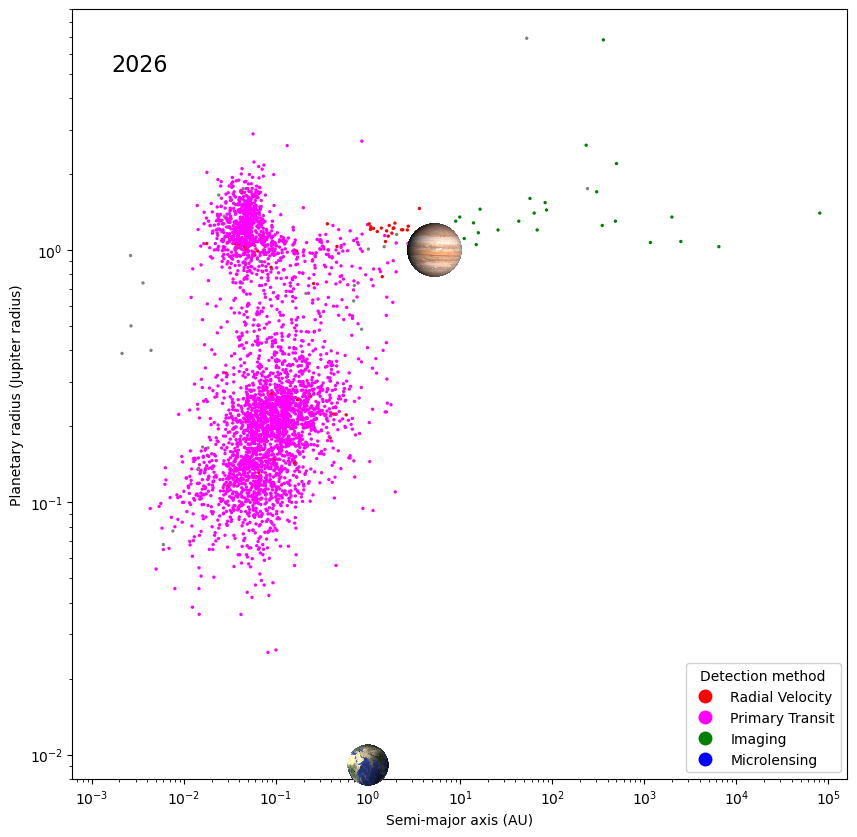

In [20]:
# Drop rows missing any needed value

color_map = {
    'Radial Velocity' : 'red',
    'Primary Transit' : 'magenta',
    'Imaging' : 'green',
    'Microlensing' : 'blue'
}

df['color'] = df['detection_type'].map(color_map).fillna('gray')
years = np.arange(df['discovered'].min(), df['discovered'].max() + 1)

fig, ax = plt.subplots(figsize=(10,10))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(df['semi_major_axis'].min() * 0.5, df['semi_major_axis'].max() * 2)
ax.set_ylim(0.008, 9)
ax.set_xlabel('Semi-major axis (AU)')
ax.set_ylabel('Planetary radius (Jupiter radius)')

# Create Legend
handles = [
    Line2D([0], [0], marker='o', linestyle='', markersize=10,
           markerfacecolor=c, markeredgecolor='none', label=label)
    for label, c in color_map.items()
]

legend = ax.legend(handles=handles, title='Detection method',
                   loc='lower right', framealpha=0.9)

# Setting scatterplot proper
scat = ax.scatter([], [], s=2)
year_text = ax.text(0.05, 0.92, '', transform=ax.transAxes, fontsize=16)

img = plt.imread('jupiter.png')            # ideally a PNG with a transparent background
imagebox = OffsetImage(img, zoom=0.05)     # adjust zoom to taste

jupiter = AnnotationBbox(
    imagebox,
    (5.2,1),            # (mass in M_j, semi major axis in AU)
    xycoords='data',
    frameon=False,           # no border box around the image
    box_alignment=(0.5, 0.5),  # image center sits on the point
    zorder=10,               # draw above the scatter points
)
jupiter.set_animated(True)   # needed for correct layering with blit=True (see below)
ax.add_artist(jupiter)

img = plt.imread('earth.png')            # ideally a PNG with a transparent background
imagebox = OffsetImage(img, zoom=0.03)     # adjust zoom to taste

earth = AnnotationBbox(
    imagebox,
    (1, 0.0091),            # (mass in M_j, semi major axis in AU)
    xycoords='data',
    frameon=False,           # no border box around the image
    box_alignment=(0.5, 0.5),  # image center sits on the point
    zorder=10,               # draw above the scatter points
)
earth.set_animated(True)   # needed for correct layering with blit=True (see below)
ax.add_artist(earth)

def update(year):
    seen = df[df['discovered'] <= year]
    scat.set_offsets(seen[['semi_major_axis', 'radius']].to_numpy())

    scat.set_facecolor(seen['color'])

    year_text.set_text(str(year))
    return scat, year_text, jupiter, earth

anim = FuncAnimation(fig, update, frames=frames, interval=300, blit=True)
anim.save('exoplanets_radius_semi.gif', writer=PillowWriter(fps=4))
plt.show()

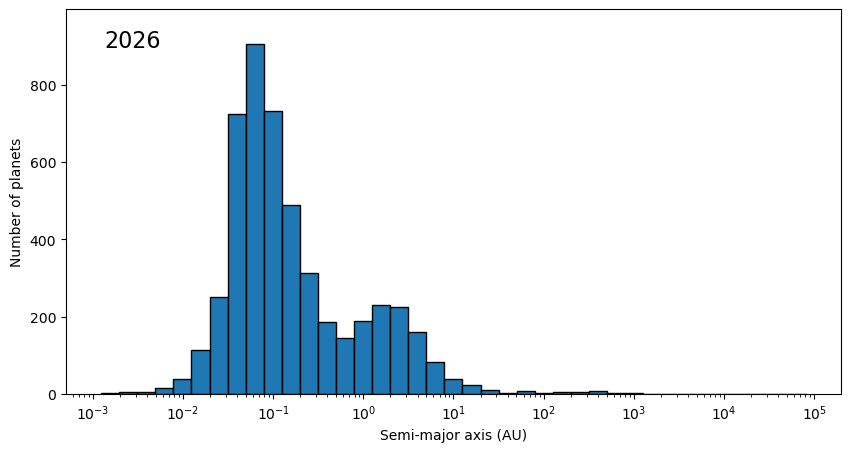

In [18]:
d = df.dropna(subset=['semi_major_axis', 'discovered'])
a = d['semi_major_axis'].to_numpy()

yr = d['discovered'].to_numpy()

bins = np.logspace(np.log10(a.min()), np.log10(a.max()), 40)
final_counts, _ = np.histogram(a, bins=bins)

fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xscale('log')
ax.set_ylim(0, final_counts.max() * 1.1)
ax.set_xlabel('Semi-major axis (AU)')
ax.set_ylabel('Number of planets')

bars = ax.bar(bins[:-1], np.zeros(len(bins) - 1),
              width=np.diff(bins), align='edge', edgecolor='black')
year_text = ax.text(0.05, 0.9, '', transform=ax.transAxes, fontsize=16)

def update(year):
    counts, _ = np.histogram(a[yr <= year], bins=bins)
    for bar, c in zip(bars, counts):
        bar.set_height(c)
    year_text.set_text(str(year))
    return (*bars, year_text)

anim = FuncAnimation(fig, update, frames=frames, interval=300, blit=True)
anim.save('exoplanets_semi_major_axis.gif', writer=PillowWriter(fps=4))

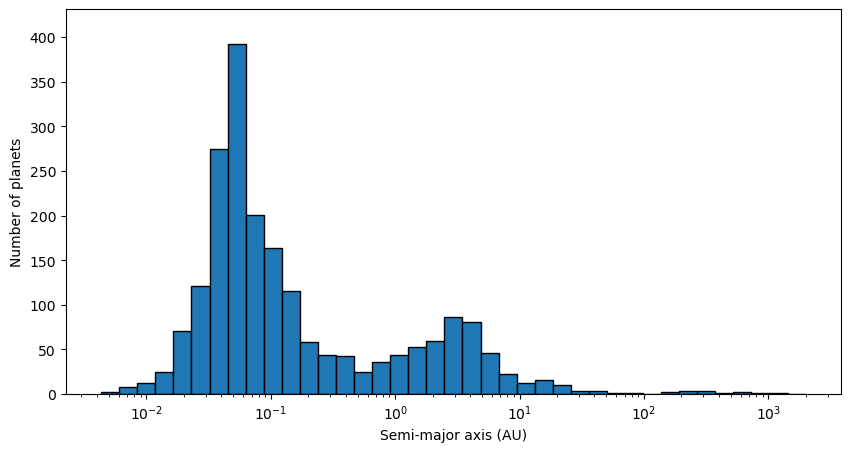

In [9]:
d = df.dropna(subset=['semi_major_axis', 'semi_major_axis_error_min', 'semi_major_axis_error_max', 'mass', 'mass_error_min', 'mass_error_max'])
a = d['semi_major_axis'].to_numpy()
err_min = d['semi_major_axis_error_min'].to_numpy()
err_max = d['semi_major_axis_error_max'].to_numpy()

bins = np.logspace(np.log10(a.min()), np.log10(a.max()), 40)
semi_all_counts = []
noisy_semis = []

for i in range(30):

    rng = np.random.default_rng()
    samples = rng.normal(loc=0.0, scale=1.0, size=len(a))

    errs = ((err_max + err_min)/2)*samples

    noisy_semi = a + errs

    final_counts, _ = np.histogram(noisy_semi, bins=bins)
    noisy_semis.append(noisy_semi)

    semi_all_counts.append(final_counts)

semi_all_counts = np.array(semi_all_counts)
noisy_semis = np.array(noisy_semis)

fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xscale('log')
ax.set_ylim(0, final_counts.max() * 1.1)
ax.set_xlabel('Semi-major axis (AU)')
ax.set_ylabel('Number of planets')

bars = ax.bar(bins[:-1], np.zeros(len(bins) - 1),
              width=np.diff(bins), align='edge', edgecolor='black')
year_text = ax.text(0.05, 0.9, '', transform=ax.transAxes, fontsize=16)

def update(i):

    for bar, c in zip(bars, semi_all_counts[i]):
        bar.set_height(c)                          # use set_height for the vertical version
    
    return (*bars,)

anim = FuncAnimation(fig, update, frames=30, interval=400, blit=True)
anim.save('exoplanets_semi_major_axis_noisy.gif', writer=PillowWriter(fps=4))

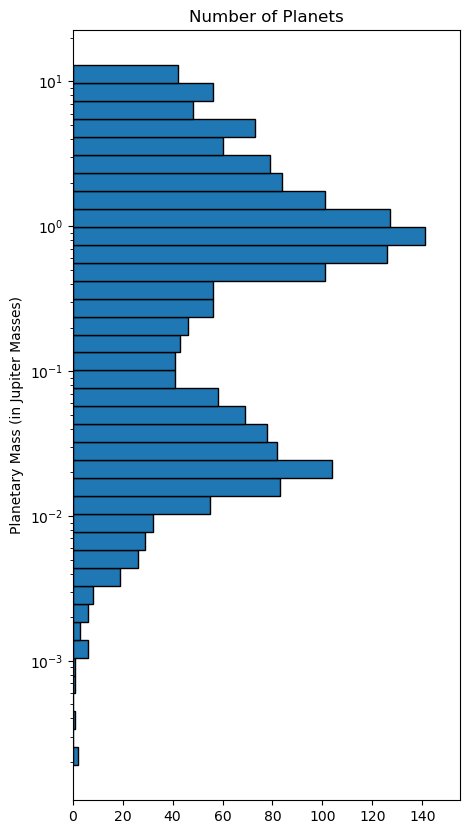

In [10]:
a = d['mass'].to_numpy()
err_min = d['mass_error_min'].to_numpy()
err_max = d['mass_error_max'].to_numpy()


bins = np.logspace(np.log10(a.min()), np.log10(a.max()), 40)
masses_all_counts = []
noisy_masses = []

for i in range(30):

    rng = np.random.default_rng()
    samples = rng.normal(loc=0.0, scale=1.0, size=len(a))

    errs = ((err_max + err_min)/2)*samples
    noisy_mass = a + errs

    final_counts, _ = np.histogram(noisy_mass, bins=bins)
    noisy_masses.append(noisy_mass)
    masses_all_counts.append(final_counts)

masses_all_counts = np.array(masses_all_counts)
noisy_masses = np.array(noisy_masses)

fig, ax = plt.subplots(figsize=(5, 10))
ax.set_yscale('log')
ax.set_xlim(0, final_counts.max() * 1.1)
ax.set_title('Number of Planets')
ax.set_ylabel('Planetary Mass (in Jupiter Masses)')

bars = ax.barh(bins[:-1], np.zeros(len(bins) - 1),
              height=np.diff(bins), align='edge', edgecolor='black')
year_text = ax.text(0.05, 0.9, '', transform=ax.transAxes, fontsize=16)

def update(i):

    for bar, c in zip(bars, masses_all_counts[i]):
        bar.set_width(c)                          # use set_height for the vertical version
    
    return (*bars,)

anim = FuncAnimation(fig, update, frames=30, interval=400, blit=True)
anim.save('exoplanets_masses_noisy.gif', writer=PillowWriter(fps=4))

In [174]:
np.shape(noisy_masses)

(30, 2051)

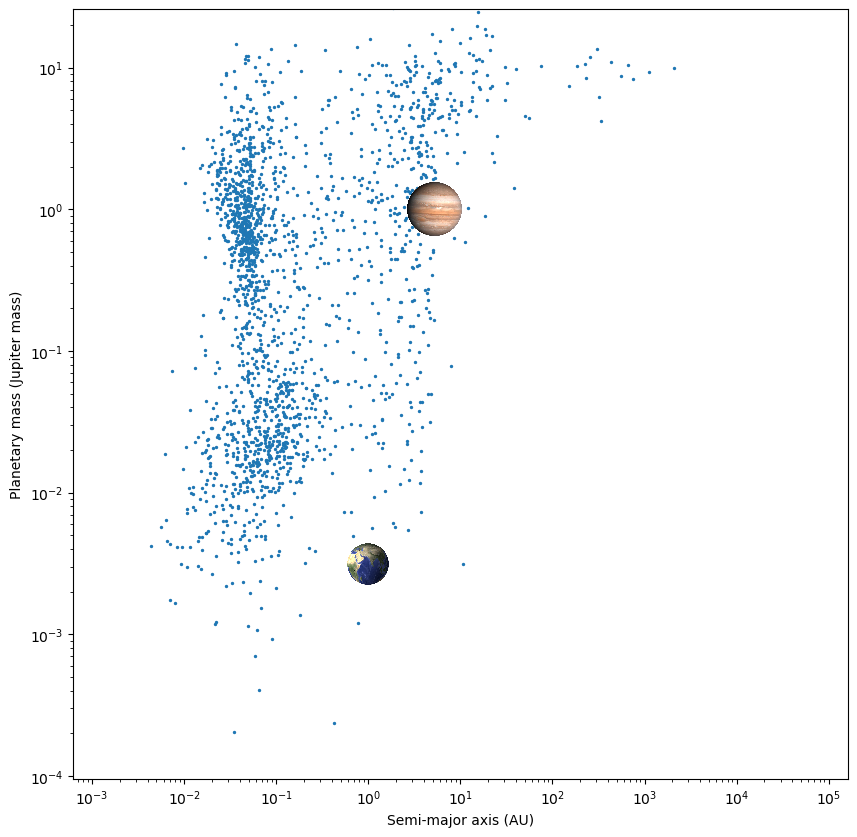

In [11]:
fig, ax = plt.subplots(figsize=(10,10))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(df['semi_major_axis'].min() * 0.5, df['semi_major_axis'].max() * 2)
ax.set_ylim(df['mass'].min() * 0.5, df['mass'].max() * 2)
ax.set_xlabel('Semi-major axis (AU)')
ax.set_ylabel('Planetary mass (Jupiter mass)')

# Setting scatterplot proper
scat = ax.scatter([], [], s=2)


img = plt.imread('jupiter.png')            # ideally a PNG with a transparent background
imagebox = OffsetImage(img, zoom=0.05)     # adjust zoom to taste

jupiter = AnnotationBbox(
    imagebox,
    (5.2,1),            # (mass in M_j, semi major axis in AU)
    xycoords='data',
    frameon=False,           # no border box around the image
    box_alignment=(0.5, 0.5),  # image center sits on the point
    zorder=10,               # draw above the scatter points
)
jupiter.set_animated(True)   # needed for correct layering with blit=True (see below)
ax.add_artist(jupiter)

img = plt.imread('earth.png')            # ideally a PNG with a transparent background
imagebox = OffsetImage(img, zoom=0.03)     # adjust zoom to taste

earth = AnnotationBbox(
    imagebox,
    (1, 0.00315),            # (mass in M_j, semi major axis in AU)
    xycoords='data',
    frameon=False,           # no border box around the image
    box_alignment=(0.5, 0.5),  # image center sits on the point
    zorder=10,               # draw above the scatter points
)
earth.set_animated(True)   # needed for correct layering with blit=True (see below)
ax.add_artist(earth)

def update(i):
    scat.set_offsets(np.column_stack((noisy_semis[i], noisy_masses[i])))
    return (scat,)

anim = FuncAnimation(fig, update, frames=30, interval=400, blit=True)
anim.save('exoplanets_semi_masses_noisy.gif', writer=PillowWriter(fps=4))

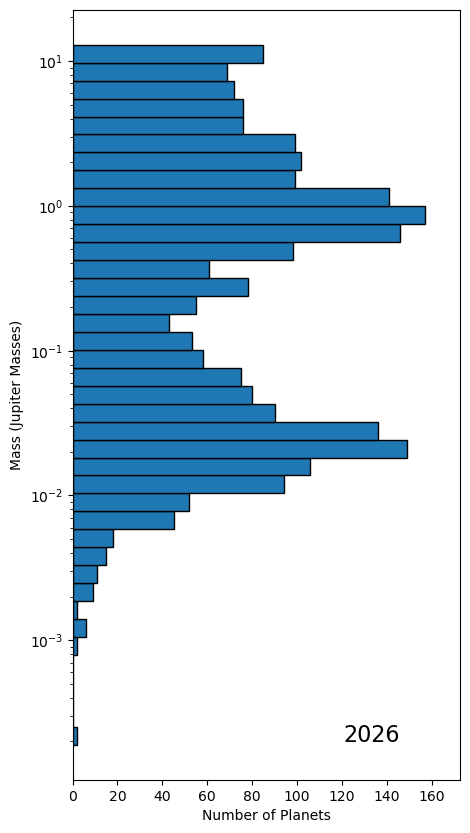

In [17]:
d = df.dropna(subset=['mass', 'discovered'])
a = d['mass'].to_numpy()

yr = d['discovered'].to_numpy()

bins = np.logspace(np.log10(a.min()), np.log10(a.max()), 40)
final_counts, _ = np.histogram(a, bins=bins)

fig, ax = plt.subplots(figsize=(5, 10))
ax.set_yscale('log')
ax.set_xlim(0, final_counts.max() * 1.1)
ax.set_xlabel('Number of Planets')
ax.set_ylabel('Mass (Jupiter Masses)')

bars = ax.barh(bins[:-1], np.zeros(len(bins) - 1),
              height=np.diff(bins), align='edge', edgecolor='black')
year_text = ax.text(0.7, 0.05, '', transform=ax.transAxes, fontsize=16)

def update(year):
    counts, _ = np.histogram(a[yr <= year], bins=bins)
    for bar, c in zip(bars, counts):
        bar.set_width(c)
    year_text.set_text(str(year))
    return (*bars, year_text)

anim = FuncAnimation(fig, update, frames=frames, interval=300, blit=True)
anim.save('exoplanets_masses.gif', writer=PillowWriter(fps=4))